In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsforecast.models import AutoARIMA, AutoETS

url = 'https://raw.githubusercontent.com/Nixtla/transfer-learning-time-series/main/datasets/air_passengers.csv'
df = pd.read_csv(url)
df

/home/ravikumar/Projects/learning-forecasting/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,timestamp,value
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132
3,1949-04-01,129
4,1949-05-01,121
...,...,...
139,1960-08-01,606
140,1960-09-01,508
141,1960-10-01,461
142,1960-11-01,390


In [2]:
df = df.rename(columns={'timestamp': 'ds', 'value': 'y'})
df['ds'] = pd.to_datetime(df['ds'])
df['unique_id'] = 'air_passengers'
df

,ds,y,unique_id
0,1949-01-01,112,air_passengers
1,1949-02-01,118,air_passengers
2,1949-03-01,132,air_passengers
3,1949-04-01,129,air_passengers
4,1949-05-01,121,air_passengers
...,...,...,...
139,1960-08-01,606,air_passengers
140,1960-09-01,508,air_passengers
141,1960-10-01,461,air_passengers
142,1960-11-01,390,air_passengers


        unique_id metric  AutoARIMA
0  air_passengers    mae  18.515821
1  air_passengers   mape   0.041797


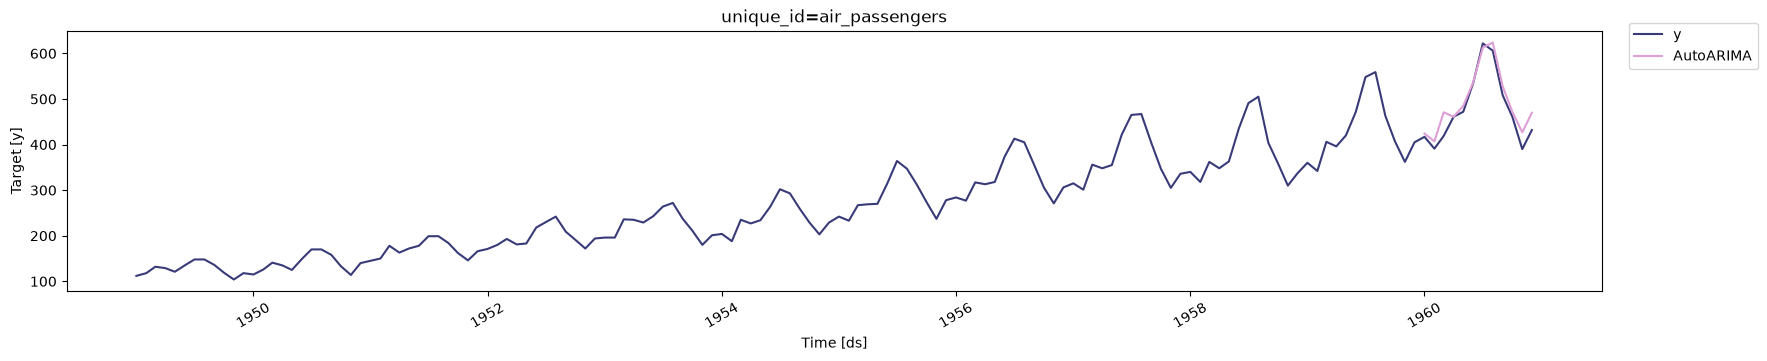

In [6]:
from statsforecast import StatsForecast
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mae, mape
train = df.head(-12)
test = df.tail(12)

sf = StatsForecast(
    models=[AutoARIMA(season_length=12)],
    freq="MS",
    n_jobs=-1
)

forecast_df = sf.forecast(df=train, h=12)
comparison_df = test.merge(forecast_df, on=['unique_id', 'ds'])

metrics = [mae, mape]
scores = evaluate(
    df=comparison_df,
    metrics=[mae, mape],
    models=['AutoARIMA'],
    target_col='y',
    id_col='unique_id'
)
print(scores)

sf.plot(df, forecast_df)

In [9]:
from mlforecast import MLForecast
from mlforecast.target_transforms import Differences
from mlforecast.lag_transforms import RollingMean
import lightgbm as lgb

# 2. Instantiate the LightGBM Regressor
# We pass standard scikit-learn compatible hyperparameters
lgb_model = lgb.LGBMRegressor(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42,
    verbosity=-1
)

# 3. Setup the MLForecast Pipeline
fcst = MLForecast(
    models=[lgb_model],
    freq='MS',                             # Month Start frequency
    lags=[1, 12],                       # Features: y_(t-1), y_(t-2), y_(t-12)
    lag_transforms={
        1: [RollingMean(window_size=12)]   # Feature: 12-month rolling average based on lag 1
    },
    target_transforms=[Differences([1, 12])],
    date_features=['month']                # Feature: Extract month integer from 'ds'
)

# 4. Train the model
# This builds the tabular matrix under the hood and fits the LightGBM Regressor
fcst.fit(train)

# 5. Predict the next 12 months
# It dynamically updates features recursively at each forecasting step
forecast_df = fcst.predict(h=12)
print("--- LightGBM Forecasts ---")
print(forecast_df.head())

# 6. Evaluate alongside actual test data
comparison_df = test.merge(forecast_df, on=['unique_id', 'ds'])

# Quick performance check using standard MAE
from sklearn.metrics import mean_absolute_error
mae_score = mean_absolute_error(comparison_df['y'], comparison_df['LGBMRegressor'])
print(f"\nLightGBM MAE: {mae_score:.2f}")

--- LightGBM Forecasts ---
        unique_id         ds  LGBMRegressor
0  air_passengers 1960-01-01     421.430847
1  air_passengers 1960-02-01     405.875244
2  air_passengers 1960-03-01     467.900360
3  air_passengers 1960-04-01     455.225769
4  air_passengers 1960-05-01     482.361816

LightGBM MAE: 19.19


In [17]:
from mlforecast import MLForecast
from mlforecast.target_transforms import Differences
from lightgbm import LGBMRegressor

fcst = MLForecast(
    models=[LGBMRegressor(random_seed=42)],
    freq='MS',
    lags=[1, 12],
    target_transforms=[Differences([1, 12])]
)

cv_results_mlf = fcst.cross_validation(
    df=df,
    h=12,
    step_size=12,
    n_windows=8
)

mlf_cv_evaluation = evaluate(
    df=cv_results_mlf,
    metrics=[mae, mape],
    models=['LGBMRegressor']
)
print("MLForecast CV Scores:\n", mlf_cv_evaluation)

MLForecast CV Scores:
          unique_id     cutoff metric  LGBMRegressor
0   air_passengers 1952-12-01    mae      11.123188
1   air_passengers 1953-12-01    mae      16.535708
2   air_passengers 1954-12-01    mae      22.043734
3   air_passengers 1955-12-01    mae       6.345627
4   air_passengers 1956-12-01    mae      14.442879
5   air_passengers 1957-12-01    mae      13.558950
6   air_passengers 1958-12-01    mae      53.706446
7   air_passengers 1959-12-01    mae      14.927017
8   air_passengers 1952-12-01   mape       0.051650
9   air_passengers 1953-12-01   mape       0.068015
10  air_passengers 1954-12-01   mape       0.075441
11  air_passengers 1955-12-01   mape       0.019302
12  air_passengers 1956-12-01   mape       0.036704
13  air_passengers 1957-12-01   mape       0.036433
14  air_passengers 1958-12-01   mape       0.125469
15  air_passengers 1959-12-01   mape       0.033668


In [18]:
# Run backtesting
# This splits the data into 3 rolling windows, predicting 12 months ahead for each
cv_results_sf = sf.cross_validation(
    df=df,
    h=12,         # Forecast horizon
    step_size=12, # Shift the window by 12 months each time
    n_windows=8   # Number of validation folds
)

# Preview the results (contains cutoffs, actuals 'y', and model predictions)
cv_results_sf.head()


,unique_id,ds,cutoff,y,AutoARIMA
0,air_passengers,1953-01-01,1952-12-01,196.0,200.033966
1,air_passengers,1953-02-01,1952-12-01,196.0,205.951263
2,air_passengers,1953-03-01,1952-12-01,236.0,228.492813
3,air_passengers,1953-04-01,1952-12-01,235.0,214.413177
4,air_passengers,1953-05-01,1952-12-01,229.0,220.835052


In [19]:
import pandas as pd

# Merge the predictions from both backtests on unique_id, ds, and cutoff
combined_cv = pd.merge(
    cv_results_sf[['unique_id', 'ds', 'cutoff', 'y', 'AutoARIMA']],
    cv_results_mlf[['unique_id', 'ds', 'cutoff', 'LGBMRegressor']],
    on=['unique_id', 'ds', 'cutoff']
)

# Calculate absolute errors
combined_cv['error_arima'] = (combined_cv['y'] - combined_cv['AutoARIMA']).abs()
combined_cv['error_lgb'] = (combined_cv['y'] - combined_cv['LGBMRegressor']).abs()

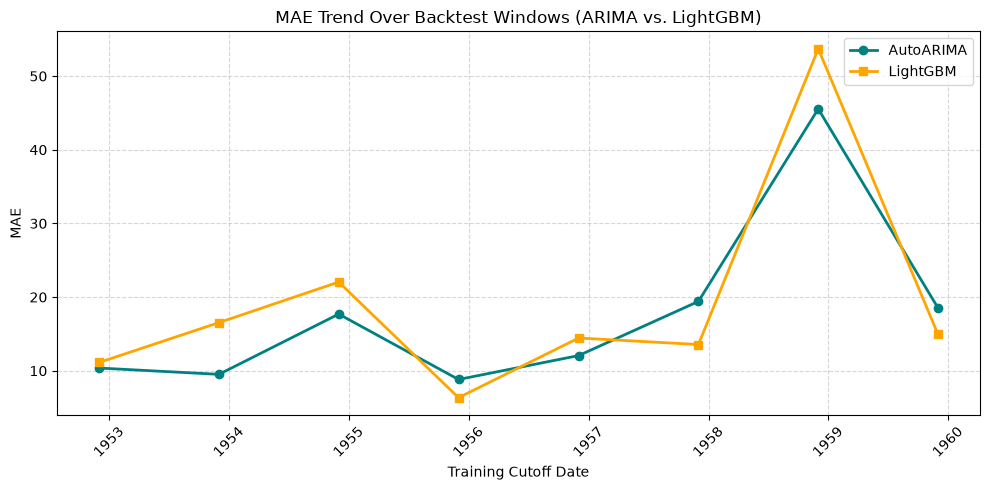

In [20]:
import matplotlib.pyplot as plt

# Group by cutoff and calculate average MAE
mae_cutoff = combined_cv.groupby('cutoff')[['error_arima', 'error_lgb']].mean().reset_index()

plt.figure(figsize=(10, 5))
plt.plot(mae_cutoff['cutoff'], mae_cutoff['error_arima'], marker='o', label='AutoARIMA', color='teal', linewidth=2)
plt.plot(mae_cutoff['cutoff'], mae_cutoff['error_lgb'], marker='s', label='LightGBM', color='orange', linewidth=2)

plt.title('MAE Trend Over Backtest Windows (ARIMA vs. LightGBM)')
plt.xlabel('Training Cutoff Date')
plt.ylabel('MAE')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

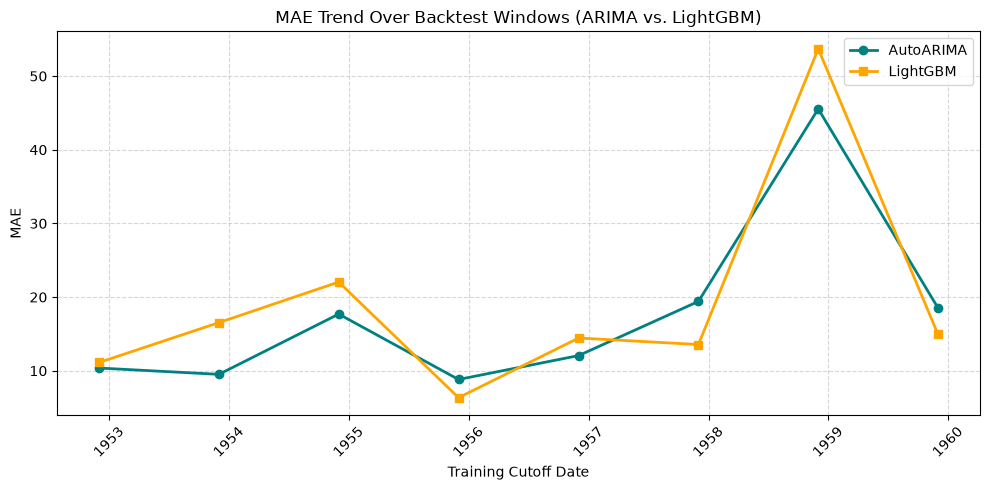

In [21]:
import matplotlib.pyplot as plt

# Group by cutoff and calculate average MAE
mae_cutoff = combined_cv.groupby('cutoff')[['error_arima', 'error_lgb']].mean().reset_index()

plt.figure(figsize=(10, 5))
plt.plot(mae_cutoff['cutoff'], mae_cutoff['error_arima'], marker='o', label='AutoARIMA', color='teal', linewidth=2)
plt.plot(mae_cutoff['cutoff'], mae_cutoff['error_lgb'], marker='s', label='LightGBM', color='orange', linewidth=2)

plt.title('MAE Trend Over Backtest Windows (ARIMA vs. LightGBM)')
plt.xlabel('Training Cutoff Date')
plt.ylabel('MAE')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()